# 02 · Análisis exploratorio — PEND del MEM (CENACE)

Precios en Nodos Distribuidos (zonas de carga) del Sistema Interconectado Nacional, mercados MDA y MTR.
Objetivo: entender la estructura de la serie antes de modelar el PML/PEND del día en adelanto.

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*p-value.*")

DATA = Path("data")
ZONA = "MONTERREY"

PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#f4f8fd", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIVERG = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])

plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=PALETA),
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 1.6, "legend.frameon": False,
})

## 1. Carga y control de calidad

In [3]:
mda = pd.read_parquet(DATA / "pend_sin_mda.parquet")
ruta_mtr = DATA / "pend_sin_mtr.parquet"
mtr = pd.read_parquet(ruta_mtr) if ruta_mtr.exists() else None

ZONAS = sorted(mda["clave"].unique())
COLOR = dict(zip(ZONAS, PALETA))
print(f"MDA: {len(mda):,} filas | {len(ZONAS)} zonas | {mda.fecha.min().date()} → {mda.fecha.max().date()}")
if mtr is not None:
    print(f"MTR: {len(mtr):,} filas | {mtr.fecha.min().date()} → {mtr.fecha.max().date()}")

MDA: 685,632 filas | 8 zonas | 2017-01-27 → 2026-11-06
MTR: 684,288 filas | 2017-01-27 → 2026-10-30


In [4]:
def calidad(df):
    filas = []
    for clave, g in df.groupby("clave"):
        rango = pd.date_range(g.fecha.min(), g.fecha.max() + pd.Timedelta(hours=23), freq="h")
        filas.append({
            "clave": clave,
            "inicio": g.fecha.min().date(), "fin": g.fecha.max().date(),
            "filas": len(g),
            "horas_faltantes": len(rango.difference(g["timestamp"])),
            "ts_duplicados": g["timestamp"].duplicated().sum(),
            "hora_25": (g["hora"] == 25).sum(),
            "nulos_precio": g["precio"].isna().sum(),
            "residuo_comp": (g["precio"] - g[["energia", "perdidas", "congestion"]].sum(axis=1)).abs().max(),
        })
    return pd.DataFrame(filas).set_index("clave")

calidad(mda)

,inicio,fin,filas,horas_faltantes,ts_duplicados,hora_25,nulos_precio,residuo_comp
clave,,,,,,,,
ACAPULCO,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
AGUASCALIENTES,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
GUADALAJARA,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
HERMOSILLO,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
MERIDA,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
MONTERREY,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
PUEBLA,2017-01-27,2026-11-06,85704,6,6,6,0,0.02
QUERETARO,2017-01-27,2026-11-06,85704,6,6,6,0,0.02


### Regularización horaria

Antes de 2022 el cambio de horario genera días de 23 y 25 horas. La hora 25 se promedia con la 24
y después cada zona se reindexa a una malla horaria completa. Huecos de hasta 3 h se interpolan;
los más largos se dejan como NaN y quedan marcados.

In [5]:
COLS = ["precio", "energia", "perdidas", "congestion"]

def regularizar(df, max_gap=3):
    df = df.copy()
    df.loc[df["hora"] == 25, "hora"] = 24
    df = df.groupby(["clave", "fecha", "hora"], as_index=False)[COLS].mean()
    df["timestamp"] = df["fecha"] + pd.to_timedelta(df["hora"] - 1, unit="h")
    df = df.drop_duplicates(["clave", "timestamp"], keep="last")

    salida = []
    for clave, g in df.groupby("clave"):
        g = g.set_index("timestamp")[COLS]
        malla = pd.date_range(g.index.min(), g.index.max(), freq="h")
        g = g.reindex(malla)
        hueco = g["precio"].isna()
        largo = hueco.groupby((~hueco).cumsum()).transform("sum")
        g["imputado"] = hueco & (largo <= max_gap)
        g[COLS] = g[COLS].interpolate(limit_area="inside").where(~hueco | g["imputado"])
        g["clave"] = clave
        salida.append(g)
    out = pd.concat(salida).rename_axis("timestamp").reset_index()
    return out[["clave", "timestamp", *COLS, "imputado"]]

mda_c = regularizar(mda)
mtr_c = regularizar(mtr) if mtr is not None else None

resumen = mda_c.groupby("clave").agg(horas=("precio", "size"),
                                     imputadas=("imputado", "sum"),
                                     sin_dato=("precio", lambda s: s.isna().sum()))
resumen

,horas,imputadas,sin_dato
clave,,,
ACAPULCO,85704,6,0
AGUASCALIENTES,85704,6,0
GUADALAJARA,85704,6,0
HERMOSILLO,85704,6,0
MERIDA,85704,6,0
MONTERREY,85704,6,0
PUEBLA,85704,6,0
QUERETARO,85704,6,0


## 2. Panorama general

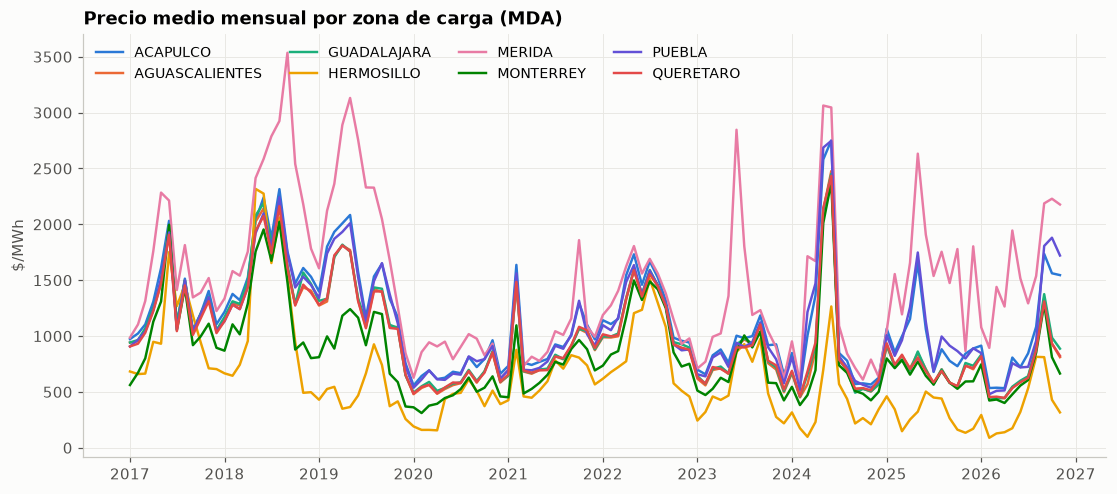

In [6]:
mensual = (mda_c.set_index("timestamp").groupby("clave")["precio"]
                .resample("MS").mean().unstack(0))

fig, ax = plt.subplots(figsize=(12, 5))
for z in ZONAS:
    ax.plot(mensual.index, mensual[z], color=COLOR[z], label=z)
ax.set_title("Precio medio mensual por zona de carga (MDA)")
ax.set_ylabel("$/MWh")
ax.legend(ncol=4, loc="upper left", fontsize=9)
plt.show()

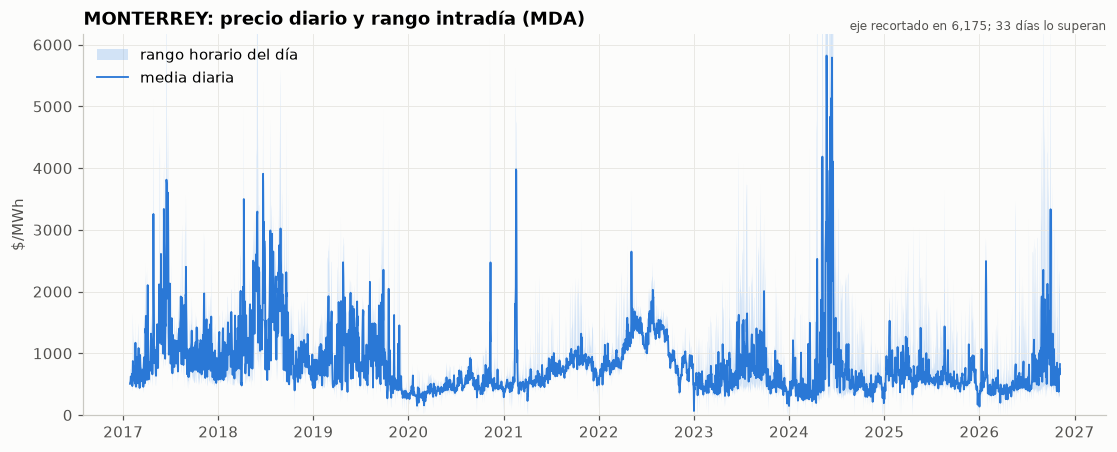

In [7]:
z = mda_c[mda_c.clave == ZONA].set_index("timestamp")["precio"]
diario = z.resample("D").agg(["mean", "min", "max"])

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(diario.index, diario["min"], diario["max"], color="#86b6ef", alpha=0.35, lw=0, label="rango horario del día")
ax.plot(diario.index, diario["mean"], color="#2a78d6", lw=1.2, label="media diaria")
ax.set_title(f"{ZONA}: precio diario y rango intradía (MDA)")
ax.set_ylabel("$/MWh")
techo = diario["max"].quantile(.99) * 1.1
ax.set_ylim(0, techo)
ax.text(1, 1.01, f"eje recortado en {techo:,.0f}; {(diario['max'] > techo).sum()} días lo superan",
        transform=ax.transAxes, ha="right", fontsize=8, color="#52514e")
ax.legend(loc="upper left")
plt.show()

## 3. Distribución y colas

In [8]:
def stats(s):
    s = s.dropna()
    return pd.Series({
        "media": s.mean(), "mediana": s.median(), "desv": s.std(),
        "asimetría": s.skew(), "curtosis": s.kurt(),
        "p1": s.quantile(.01), "p99": s.quantile(.99), "max": s.max(),
        "max/p99": s.max() / s.quantile(.99),
        "% ≤ 0": 100 * (s <= 0).mean(),
    })

mda_c.groupby("clave")["precio"].apply(stats).unstack().round(2)

,media,mediana,desv,asimetría,curtosis,p1,p99,max,max/p99,% ≤ 0
clave,,,,,,,,,,
ACAPULCO,1138.22,922.32,798.75,4.43,56.64,322.20,3826.99,28483.39,7.44,0.11
AGUASCALIENTES,991.85,794.92,720.31,4.88,66.78,260.00,3325.99,26352.90,7.92,0.11
GUADALAJARA,1005.20,809.34,719.30,4.61,60.12,257.58,3326.12,25546.54,7.68,0.12
HERMOSILLO,629.34,463.10,681.00,4.97,58.41,11.10,3100.98,22953.62,7.40,0.54
MERIDA,1487.66,1057.01,1350.12,3.87,27.09,343.09,6419.85,29010.79,4.52,0.10
MONTERREY,846.14,656.79,668.87,5.76,83.92,226.75,3136.50,25904.13,8.26,0.12
PUEBLA,1110.23,886.92,800.03,4.01,45.20,306.56,3891.26,26780.91,6.88,0.11
QUERETARO,989.94,794.20,710.30,4.92,68.16,272.09,3257.37,26236.75,8.05,0.13


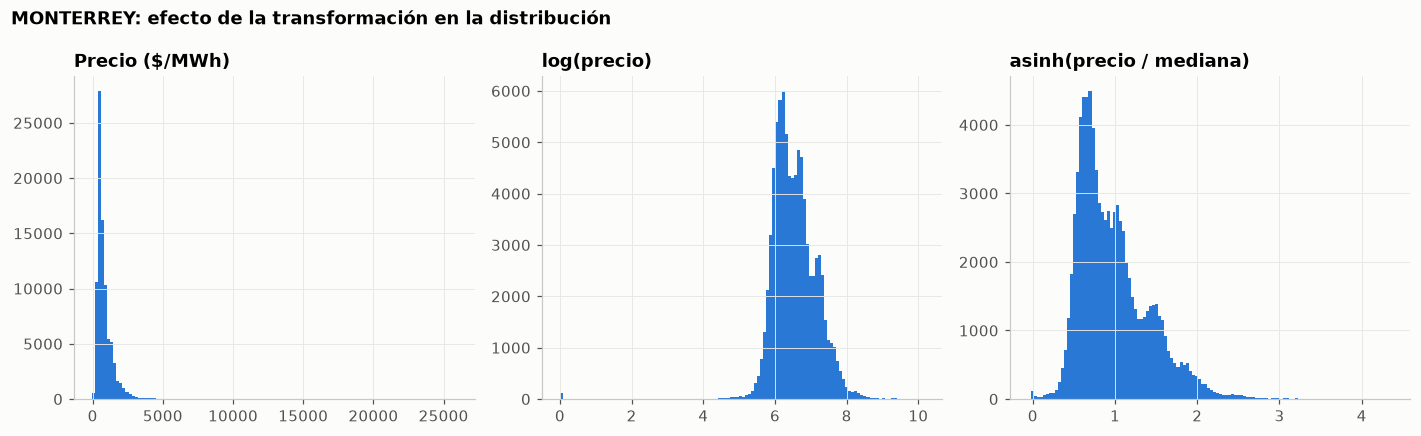

In [9]:
s = mda_c.loc[mda_c.clave == ZONA, "precio"].dropna()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(s, bins=120, color="#2a78d6")
axes[0].set_title("Precio ($/MWh)")
axes[1].hist(np.log(s.clip(lower=1)), bins=120, color="#2a78d6")
axes[1].set_title("log(precio)")
axes[2].hist(np.arcsinh(s / s.median()), bins=120, color="#2a78d6")
axes[2].set_title("asinh(precio / mediana)")
fig.suptitle(f"{ZONA}: efecto de la transformación en la distribución", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Estacionalidad

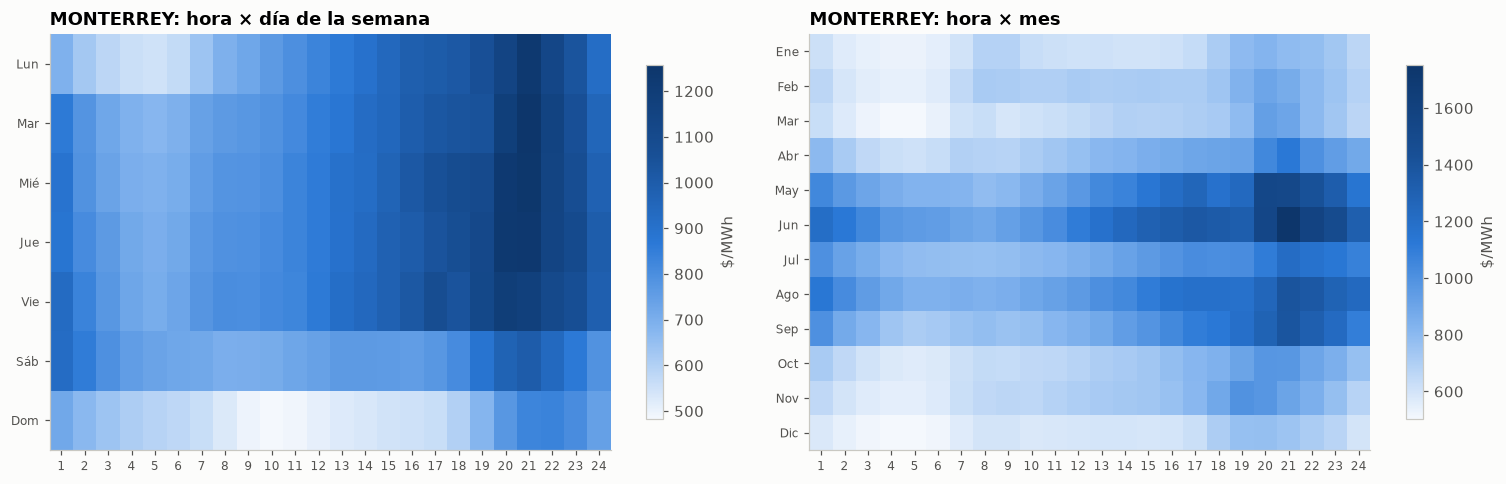

In [10]:
zz = mda_c[mda_c.clave == ZONA].dropna(subset=["precio"]).copy()
zz["hora"] = zz.timestamp.dt.hour + 1
zz["dow"] = zz.timestamp.dt.dayofweek
zz["mes"] = zz.timestamp.dt.month
zz["anio"] = zz.timestamp.dt.year

dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

def heatmap(ax, tabla, xlabels, ylabels, titulo, cmap=AZUL, etiqueta="$/MWh", **kw):
    im = ax.imshow(tabla.values, aspect="auto", cmap=cmap, **kw)
    ax.set_xticks(range(len(xlabels)), xlabels, fontsize=8)
    ax.set_yticks(range(len(ylabels)), ylabels, fontsize=8)
    ax.grid(False)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label=etiqueta, shrink=0.85)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
heatmap(axes[0], zz.pivot_table("precio", "dow", "hora"), range(1, 25), dias, f"{ZONA}: hora × día de la semana")
heatmap(axes[1], zz.pivot_table("precio", "mes", "hora"), range(1, 25), meses, f"{ZONA}: hora × mes")
plt.tight_layout()
plt.show()

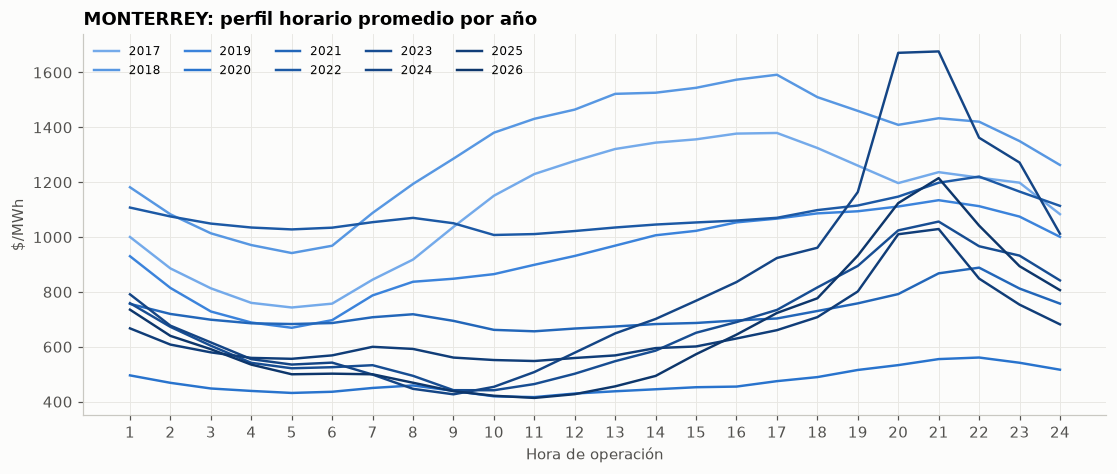

In [11]:
perfil = zz.pivot_table("precio", "hora", "anio")
anios = perfil.columns
tonos = AZUL(np.linspace(0.3, 1, len(anios)))

fig, ax = plt.subplots()
for a, c in zip(anios, tonos):
    ax.plot(perfil.index, perfil[a], color=c, label=str(a))
ax.set_title(f"{ZONA}: perfil horario promedio por año")
ax.set_xlabel("Hora de operación")
ax.set_ylabel("$/MWh")
ax.set_xticks(range(1, 25))
ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.show()

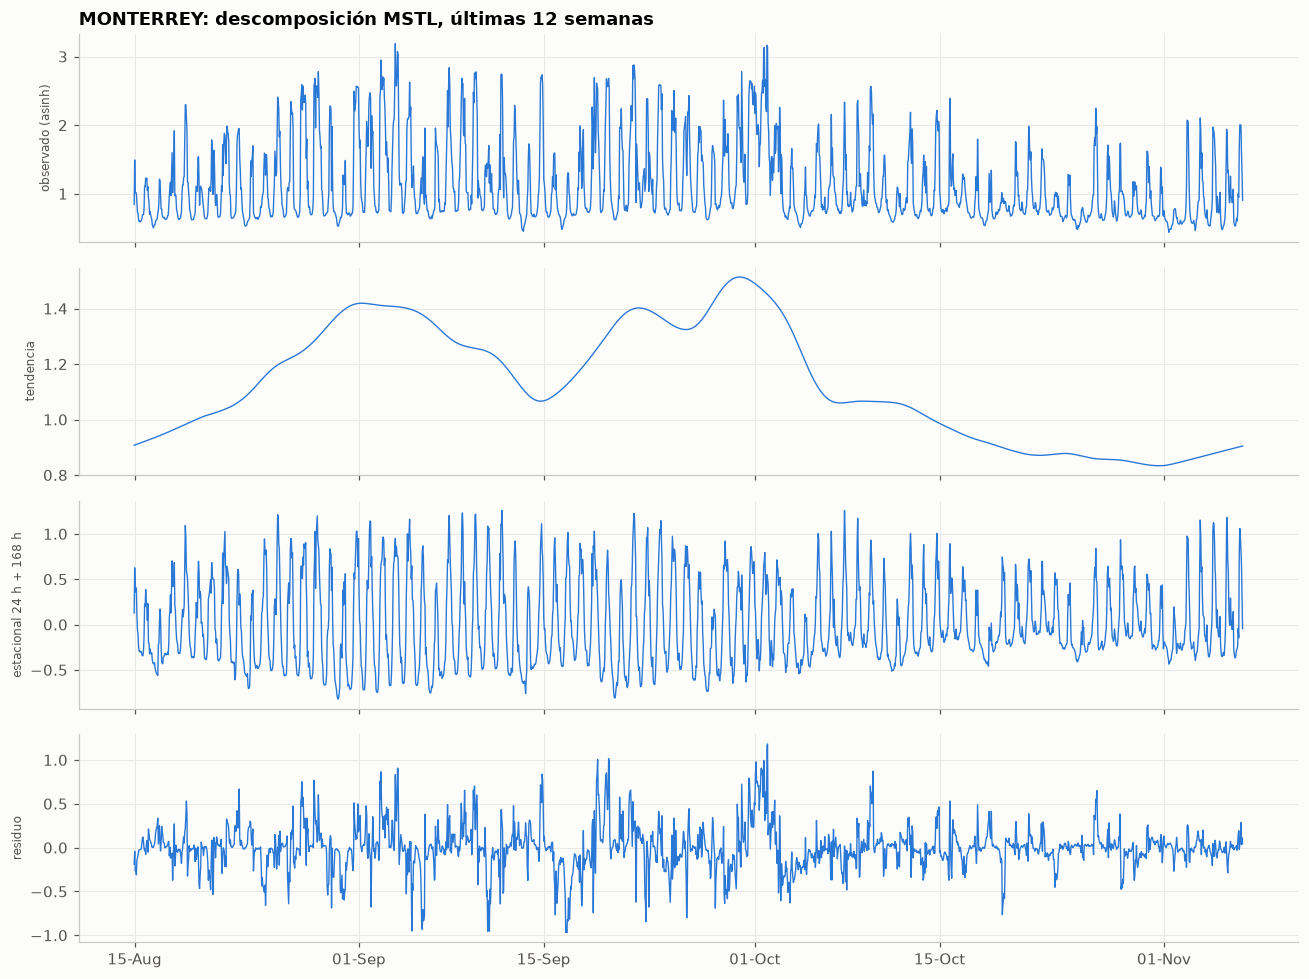

Fuerza estacional: 0.77
Fuerza de tendencia: 0.43


In [12]:
y = zz.set_index("timestamp")["precio"].asfreq("h").interpolate()
ultimo = y.loc[y.index.max() - pd.Timedelta(weeks=12):]
res = MSTL(np.arcsinh(ultimo / ultimo.median()), periods=(24, 168)).fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (serie, nombre) in zip(axes, [(res.observed, "observado (asinh)"), (res.trend, "tendencia"),
                                     (res.seasonal.sum(axis=1), "estacional 24 h + 168 h"), (res.resid, "residuo")]):
    ax.plot(serie.index, serie, color="#2a78d6", lw=0.9)
    ax.set_ylabel(nombre, fontsize=8)
axes[0].set_title(f"{ZONA}: descomposición MSTL, últimas 12 semanas")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
plt.tight_layout()
plt.show()

var = lambda s: np.nanvar(s)
print(f"Fuerza estacional: {max(0, 1 - var(res.resid) / var(res.resid + res.seasonal.sum(axis=1))):.2f}")
print(f"Fuerza de tendencia: {max(0, 1 - var(res.resid) / var(res.resid + res.trend)):.2f}")

## 5. Autocorrelación y estacionariedad

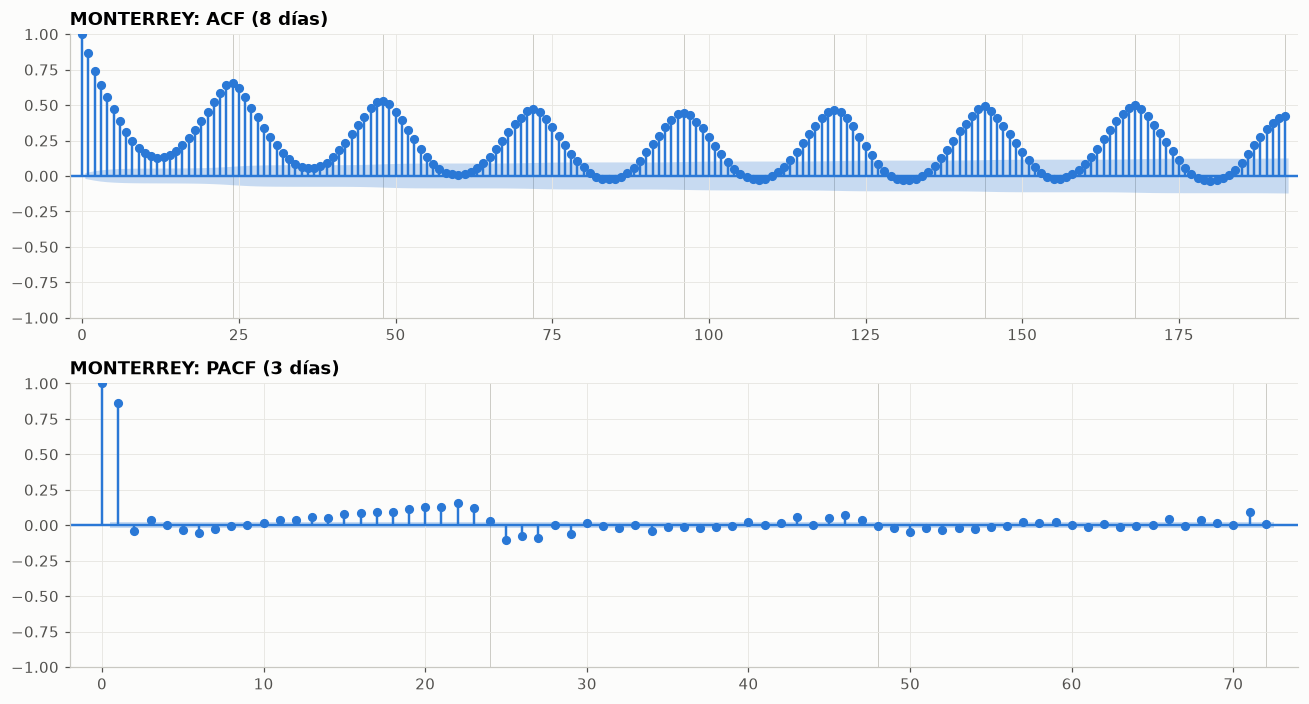

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
plot_acf(y.iloc[-24 * 365:], lags=24 * 8, ax=axes[0], color="#2a78d6", vlines_kwargs={"colors": "#2a78d6"})
plot_pacf(y.iloc[-24 * 365:], lags=24 * 3, ax=axes[1], method="ywm", color="#2a78d6", vlines_kwargs={"colors": "#2a78d6"})
for ax, dias_ in zip(axes, (8, 3)):
    for k in range(24, 24 * dias_ + 1, 24):
        ax.axvline(k, color="#c9c8c2", lw=0.6, zorder=0)
    ax.set_xlim(-2, 24 * dias_ + 2)
axes[0].set_title(f"{ZONA}: ACF (8 días)")
axes[1].set_title(f"{ZONA}: PACF (3 días)")
plt.tight_layout()
plt.show()

In [14]:
muestra = y.iloc[-24 * 365:]
pruebas = {}
for nombre, s in [("nivel", muestra), ("Δ1", muestra.diff().dropna()), ("Δ24", muestra.diff(24).dropna())]:
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    pruebas[nombre] = {"ADF p": adf_p, "KPSS p": kpss_p,
                       "lectura": "estacionaria" if adf_p < .05 and kpss_p > .05 else "no concluyente / no estacionaria"}
pd.DataFrame(pruebas).T

,ADF p,KPSS p,lectura
nivel,0.0,0.01,no concluyente / no estacionaria
Δ1,0.0,0.1,estacionaria
Δ24,0.0,0.1,estacionaria


## 6. Componentes del precio: energía, pérdidas y congestión

In [15]:
comp = mda_c.groupby("clave")[["energia", "perdidas", "congestion"]].mean()
comp["% pérdidas"] = 100 * comp["perdidas"] / mda_c.groupby("clave")["precio"].mean()
comp["% congestión"] = 100 * comp["congestion"] / mda_c.groupby("clave")["precio"].mean()
comp["% horas |cng| > 10"] = mda_c.assign(c=mda_c.congestion.abs() > 10).groupby("clave")["c"].mean() * 100
comp.round(2).sort_values("% congestión")

,energia,perdidas,congestion,% pérdidas,% congestión,% horas |cng| > 10
clave,,,,,,
HERMOSILLO,971.06,-101.60,-240.12,-16.14,-38.16,74.67
MONTERREY,971.08,-59.87,-65.06,-7.08,-7.69,51.86
QUERETARO,971.08,12.94,5.92,1.31,0.60,14.31
AGUASCALIENTES,971.08,13.40,7.37,1.35,0.74,29.42
GUADALAJARA,971.08,19.13,15.00,1.90,1.49,39.03
ACAPULCO,971.08,97.81,69.32,8.59,6.09,24.87
PUEBLA,971.08,42.69,96.45,3.85,8.69,28.27
MERIDA,971.08,165.38,351.20,11.12,23.61,39.93


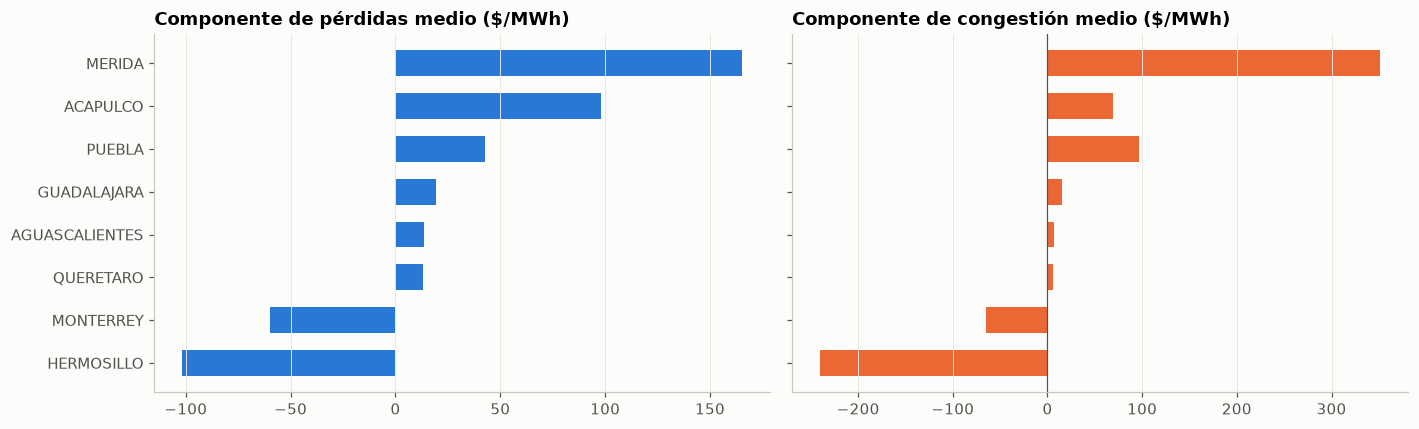

In [16]:
orden = comp.sort_values("perdidas").index
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
axes[0].barh(orden, comp.loc[orden, "perdidas"], color="#2a78d6", height=0.6)
axes[0].set_title("Componente de pérdidas medio ($/MWh)")
axes[1].barh(orden, comp.loc[orden, "congestion"], color="#eb6834", height=0.6)
axes[1].axvline(0, color="#52514e", lw=0.8)
axes[1].set_title("Componente de congestión medio ($/MWh)")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

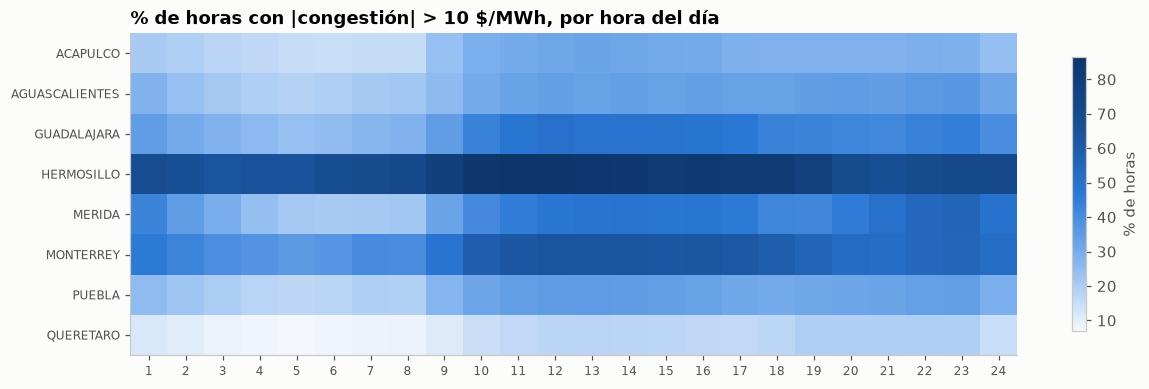

In [17]:
cng = (mda_c.assign(hora=mda_c.timestamp.dt.hour + 1, cng=mda_c.congestion.abs() > 10)
            .pivot_table("cng", "clave", "hora") * 100)
fig, ax = plt.subplots(figsize=(13, 3.8))
heatmap(ax, cng, range(1, 25), cng.index, "% de horas con |congestión| > 10 $/MWh, por hora del día", etiqueta="% de horas")
plt.show()

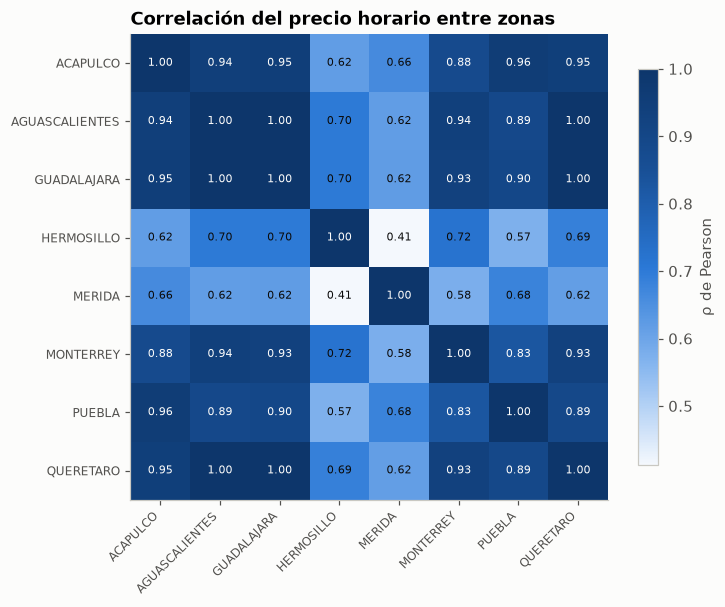

In [18]:
ancho = mda_c.pivot_table("precio", "timestamp", "clave")
corr = ancho.corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
heatmap(ax, corr, corr.columns, corr.index, "Correlación del precio horario entre zonas",
        etiqueta="ρ de Pearson", vmin=corr.values.min(), vmax=1)
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="#fcfcfb" if v > corr.values.min() + 0.6 * (1 - corr.values.min()) else "#0b0b0b")
plt.show()

## 7. Spread MTR − MDA

,media,mediana,desv,p5,p95,pct_mtr_mayor
clave,,,,,,
ACAPULCO,-8.85,-13.12,681.68,-773.80,750.81,44.71
AGUASCALIENTES,27.43,-1.47,599.60,-545.13,682.99,49.11
GUADALAJARA,23.51,-2.25,595.41,-556.14,679.25,48.76
HERMOSILLO,79.10,16.23,618.95,-440.84,949.82,61.53
MERIDA,-117.07,-25.96,1168.44,-1705.10,1023.71,41.86
MONTERREY,60.12,4.95,577.85,-425.05,742.97,52.84
PUEBLA,-21.26,-10.99,697.40,-846.37,748.17,45.15
QUERETARO,26.45,-1.71,596.53,-554.07,677.29,49.02


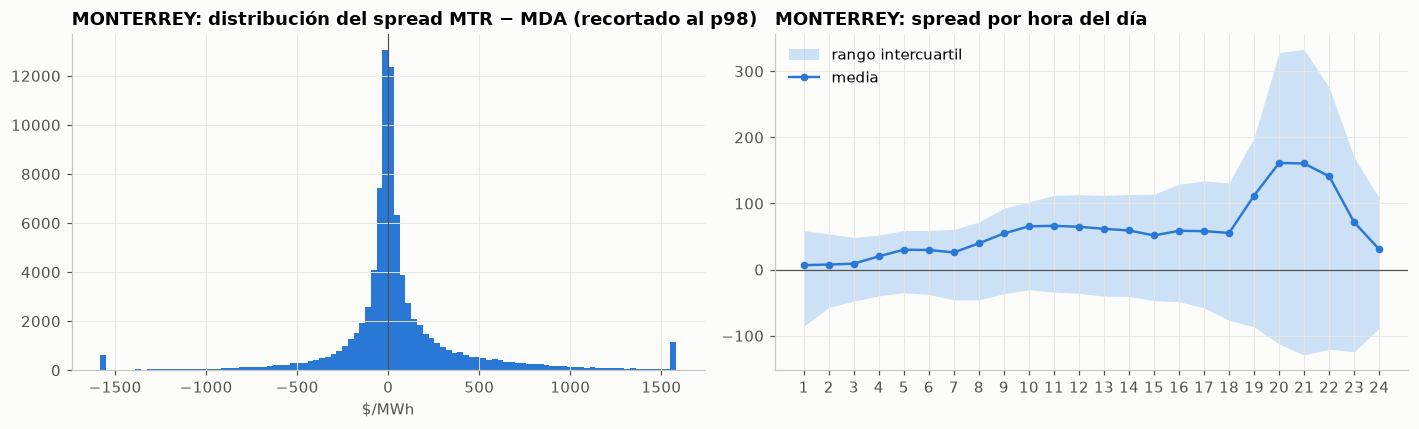

In [19]:
if mtr_c is None:
    print("No hay archivo MTR; se omite esta sección.")
else:
    sp = (mda_c[["clave", "timestamp", "precio"]]
          .merge(mtr_c[["clave", "timestamp", "precio"]], on=["clave", "timestamp"], suffixes=("_mda", "_mtr"))
          .dropna())
    sp["spread"] = sp["precio_mtr"] - sp["precio_mda"]
    sp["hora"] = sp.timestamp.dt.hour + 1

    tabla = sp.groupby("clave")["spread"].agg(
        media="mean", mediana="median", desv="std",
        p5=lambda s: s.quantile(.05), p95=lambda s: s.quantile(.95),
        pct_mtr_mayor=lambda s: 100 * (s > 0).mean())
    display(tabla.round(2))

    s = sp.loc[sp.clave == ZONA]
    lim = s["spread"].abs().quantile(.98)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(s["spread"].clip(-lim, lim), bins=100, color="#2a78d6")
    axes[0].axvline(0, color="#52514e", lw=0.8)
    axes[0].set_title(f"{ZONA}: distribución del spread MTR − MDA (recortado al p98)")
    axes[0].set_xlabel("$/MWh")
    por_hora = s.groupby("hora")["spread"].agg(["mean", lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
    por_hora.columns = ["media", "q25", "q75"]
    axes[1].fill_between(por_hora.index, por_hora.q25, por_hora.q75, color="#86b6ef", alpha=0.4, lw=0, label="rango intercuartil")
    axes[1].plot(por_hora.index, por_hora.media, color="#2a78d6", marker="o", ms=4, label="media")
    axes[1].axhline(0, color="#52514e", lw=0.8)
    axes[1].set_title(f"{ZONA}: spread por hora del día")
    axes[1].set_xticks(range(1, 25))
    axes[1].legend(loc="upper left")
    plt.tight_layout()
    plt.show()

## 8. Guardar dataset limpio

In [20]:
mda_c.to_parquet(DATA / "pend_sin_mda_clean.parquet", index=False)
if mtr_c is not None:
    mtr_c.to_parquet(DATA / "pend_sin_mtr_clean.parquet", index=False)
print("Listo:", sorted(p.name for p in DATA.glob("*_clean.parquet")))

Listo: ['pend_sin_mda_clean.parquet', 'pend_sin_mtr_clean.parquet']


## Hallazgos

- **Calidad de datos:**
- **Tendencia y niveles:**
- **Colas / picos:**
- **Estacionalidad:**
- **Componentes y congestión:**
- **Spread MTR − MDA:**
- **Implicaciones para el modelado:**